In [1]:
import pandas as pd

base_url = "https://raw.githubusercontent.com/faizannadeem4449-dotcom/llm-source-attribution/main"

responses_df = pd.read_parquet(f"{base_url}/ai_responses.parquet")
prompts_df = pd.read_json(f"{base_url}/ai_prompts.jsonl", lines=True)

print("Responses Shape:", responses_df.shape)
print("Columns:", responses_df.columns.tolist())
responses_df.head(3)

Responses Shape: (9719, 11)
Columns: ['id', 'text', 'model', 'cv_group', 'prompt_group', 'n_words', 'prompt_hash', 'request_status', 'prompt_sources', 'response_license', 'kind']


,id,text,model,cv_group,prompt_group,n_words,prompt_hash,request_status,prompt_sources,response_license,kind
0,generated_0006194106fa3a592c46cac0,"Fanny packs make walking around town easier, s...",gpt-5.6-terra,ext-f32ae4c464054cd90350,ext-f32ae4c464054cd90350,61,f32ae4c464054cd903500dc81e90ade3aa3b0fc2403ca8...,autoresearch_candidate_v1,"[{""source"": ""databricks/databricks-dolly-15k"",...",not independently established,new
1,generated_00073712ffe2c3e2b449d869,Humean supervenience is David Lewis’s view tha...,gpt-5.6-terra,pg_ntlop_001101,ext-4ea91d83b97b90958e47,87,4ea91d83b97b90958e47bec19cd68729e8652e0b7474ba...,rendered_from_documented_template_not_byte_ver...,"[{""source"": ""arxitekton/ntl-claude-gen-v2"", ""p...",not independently established,gap
2,generated_001899f8ad1bc5f07b9d37de,"Elligator is a family of encodings, introduced...",gpt-5.6-terra,pg_ntlop_001665,ext-e332f7daa53b2f8c42a4,213,e332f7daa53b2f8c42a49e28e504d24c28e769fddea5c5...,rendered_from_documented_template_not_byte_ver...,"[{""source"": ""arxitekton/ntl-claude-gen-v2"", ""p...",not independently established,gap


/tmp/ipykernel_1158/3744351585.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, y='model', order=df['model'].value_counts().index, palette='viridis')


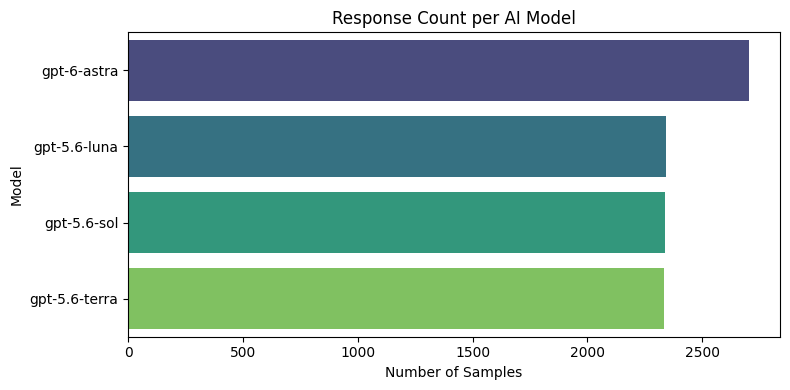

Test Accuracy: 33.49%

               precision    recall  f1-score   support

 gpt-5.6-luna       0.27      0.25      0.26       468
  gpt-5.6-sol       0.15      0.15      0.15       468
gpt-5.6-terra       0.35      0.34      0.35       467
  gpt-6-astra       0.52      0.56      0.54       541

     accuracy                           0.33      1944
    macro avg       0.32      0.33      0.32      1944
 weighted avg       0.33      0.33      0.33      1944



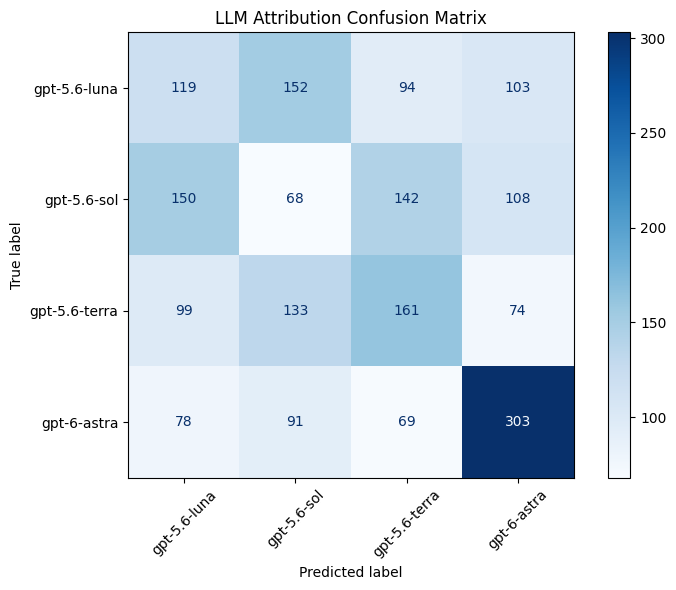

In [2]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, accuracy_score, ConfusionMatrixDisplay

# 1. Clean data using exact columns from your dataset
df = responses_df[['text', 'model']].dropna()

# 2. Visualize class distribution (how many samples per LLM)
plt.figure(figsize=(8, 4))
sns.countplot(data=df, y='model', order=df['model'].value_counts().index, palette='viridis')
plt.title("Response Count per AI Model")
plt.xlabel("Number of Samples")
plt.ylabel("Model")
plt.tight_layout()
plt.show()

# 3. Stratified Train-Test Split (80% Train, 20% Test)
X_train, X_test, y_train, y_test = train_test_split(
    df['text'].astype(str),
    df['model'],
    test_size=0.2,
    random_state=42,
    stratify=df['model']
)

# 4. Extract TF-IDF n-gram features
vectorizer = TfidfVectorizer(max_features=15000, ngram_range=(1, 2), sublinear_tf=True)
X_train_vec = vectorizer.fit_transform(X_train)
X_test_vec = vectorizer.transform(X_test)

# 5. Train Logistic Regression Classifier
clf = LogisticRegression(max_iter=1000, class_weight='balanced')
clf.fit(X_train_vec, y_train)

# 6. Print Accuracy, Classification Report & Confusion Matrix
y_pred = clf.predict(X_test_vec)
print(f"Test Accuracy: {accuracy_score(y_test, y_pred):.2%}\n")
print(classification_report(y_test, y_pred))

fig, ax = plt.subplots(figsize=(8, 6))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, ax=ax, cmap="Blues", xticks_rotation=45)
plt.title("LLM Attribution Confusion Matrix")
plt.tight_layout()
plt.show()